# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\juand\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Pregunta 1

Cada imagen tiene tama?o 64 ? 64. Cuando apliquemos `Flatten()`, ?cu?ntos valores tendr? cada ejemplo?

**Respuesta:** 64 ? 64 = **4,096 valores**.


---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


notebooks\lecture7\Challenge_Keras3_OlivettiFaces.ipynb:cell9:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


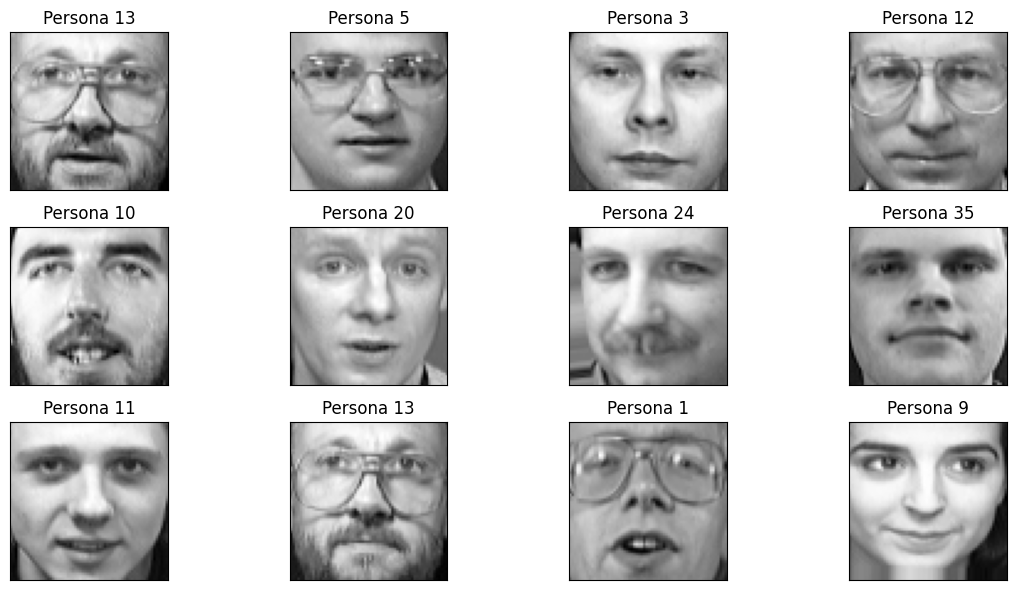

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [5]:
# TODO 1 ? Completar la arquitectura.

model = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40)
])

model.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 264,808 (1.01 MB)
 Trainable params: 264,808 (1.01 MB)
 Non-trainable params: 0 (0.00 B)


In [6]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

?Por qu? necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Convierte cada matriz de p?xeles 64?64 en el vector de 4,096 entradas que requiere la capa densa.

### Pregunta 3

?Por qu? la ?ltima capa tiene **40 neuronas**?

**Respuesta:** El conjunto tiene 40 identidades; cada salida produce el logit de una persona.

### Pregunta 4

?Qu? funci?n cumple `ReLU` en la capa oculta?

**Respuesta:** A?ade no linealidad al activar valores positivos y anular los negativos, lo que permite modelar relaciones no lineales entre p?xeles y clases.


---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [7]:
lr_rate = 0.0003  # 0.001 colaps? a una sola clase; 0.0003 permite aprender con esta configuraci?n.

# TODO 2 ? Configurar loss, optimizer y m?trica.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("? Modelo configurado.")


? Modelo configurado.


### Pregunta 5

?Por qu? usamos `from_logits=True` en la funci?n de p?rdida?

**Respuesta:** La salida del modelo son logits sin normalizar. Esta opci?n le indica a la p?rdida que los reciba como logits y aplique internamente la transformaci?n estable necesaria para calcular la entrop?a cruzada.


---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [8]:
epochs = 30
batch_size = 32

# TODO 3 ? Entrenar el modelo.

history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)


Epoch 1/30

 1/10 ━━━━━━━━━━━━━━━━━━━━ 4s 514ms/step - accuracy: 0.0312 - loss: 3.7614
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.0094 - loss: 3.7730 - val_accuracy: 0.0250 - val_loss: 3.6649
Epoch 2/30

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0625 - loss: 3.6318
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0406 - loss: 3.6581 - val_accuracy: 0.0375 - val_loss: 3.6420
Epoch 3/30

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1562 - loss: 3.5856
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0688 - loss: 3.6424 - val_accuracy: 0.0875 - val_loss: 3.6148
Epoch 4/30

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1562 - loss: 3.5426
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0562 - loss: 3.5989 - val_accuracy: 0.1000 - val_loss: 3.5939
Epoch 5/30

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1875 - loss: 3.5244
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0844 - loss: 3.5817 - val_accuracy: 0.0875 - val_loss: 

### Pregunta 6

?Qu? representa una **epoch**?

**Respuesta:** Una pasada completa por los 320 ejemplos de entrenamiento.

### Pregunta 7

?Qu? significa `batch_size=32`?

**Respuesta:** Se procesan 32 ejemplos antes de cada actualizaci?n de los par?metros (el tama?o del ?ltimo lote puede ser menor).


---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


notebooks\lecture7\Challenge_Keras3_OlivettiFaces.ipynb:cell21:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


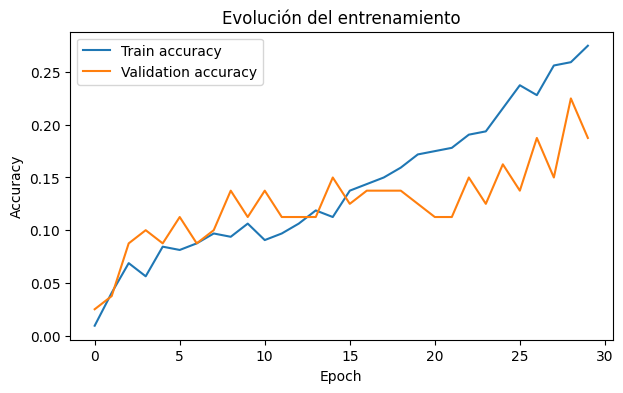

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gr?fica:

- ?El accuracy de entrenamiento sigue aumentando?
- ?El accuracy de validaci?n se comporta igual?
- ?Observas evidencia de **overfitting**?

**Respuesta:** El accuracy de entrenamiento aument? de **0.94%** en el primer epoch a **27.50%** en el ?ltimo. El de validaci?n subi? de **2.50%** a **18.75%**, con fluctuaciones. La separaci?n final de **8.75 puntos porcentuales** y la validaci?n por debajo del entrenamiento muestran una brecha de generalizaci?n compatible con overfitting, aunque ambos accuracies siguen siendo bajos.


---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [10]:
# TODO 4 ? Evaluar.

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 3.0590
Test accuracy : 0.1875
Accuracy (%)  : 18.75%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 im?genes de entrenamiento**.

?Crees que la cantidad de datos es grande o peque?a para una red con cientos de miles de par?metros?

**Respuesta:** Es peque?a: hay solo ocho ejemplos de entrenamiento por identidad para ajustar cientos de miles de par?metros. La red puede memorizar esos ejemplos y generalizar mal; la diferencia real entre accuracy de entrenamiento y validaci?n permitir? ver ese efecto.


---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


Shape de logits: (1, 40)

Primeros 10 logits:
[ 0.46149614  1.5614662  -0.5429079  -1.0588921  -0.22976364 -0.1989028
  1.0083995   0.33331534 -1.3957345  -0.21031523]


notebooks\lecture7\Challenge_Keras3_OlivettiFaces.ipynb:cell27:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


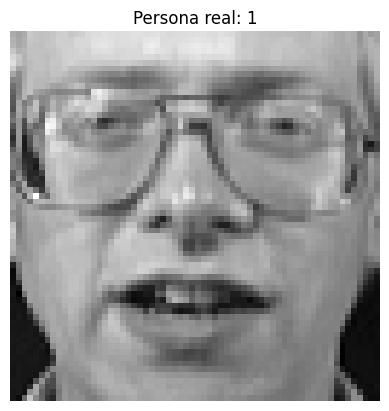

In [11]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [12]:
# TODO 5 ? Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6 ? Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)



Persona real     : 1
Persona predicha : 15


In [13]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona 15: 0.0997
Persona  1: 0.0921
Persona 18: 0.0551
Persona  6: 0.0529
Persona 31: 0.0513

Suma de probabilidades: 1.0


### Pregunta 10

?Por qu? la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Softmax divide la exponencial de cada logit por la suma de las exponenciales de las 40 clases. Por construcci?n, las salidas son no negativas y suman uno, salvo redondeo num?rico.


---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


notebooks\lecture7\Challenge_Keras3_OlivettiFaces.ipynb:cell32:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


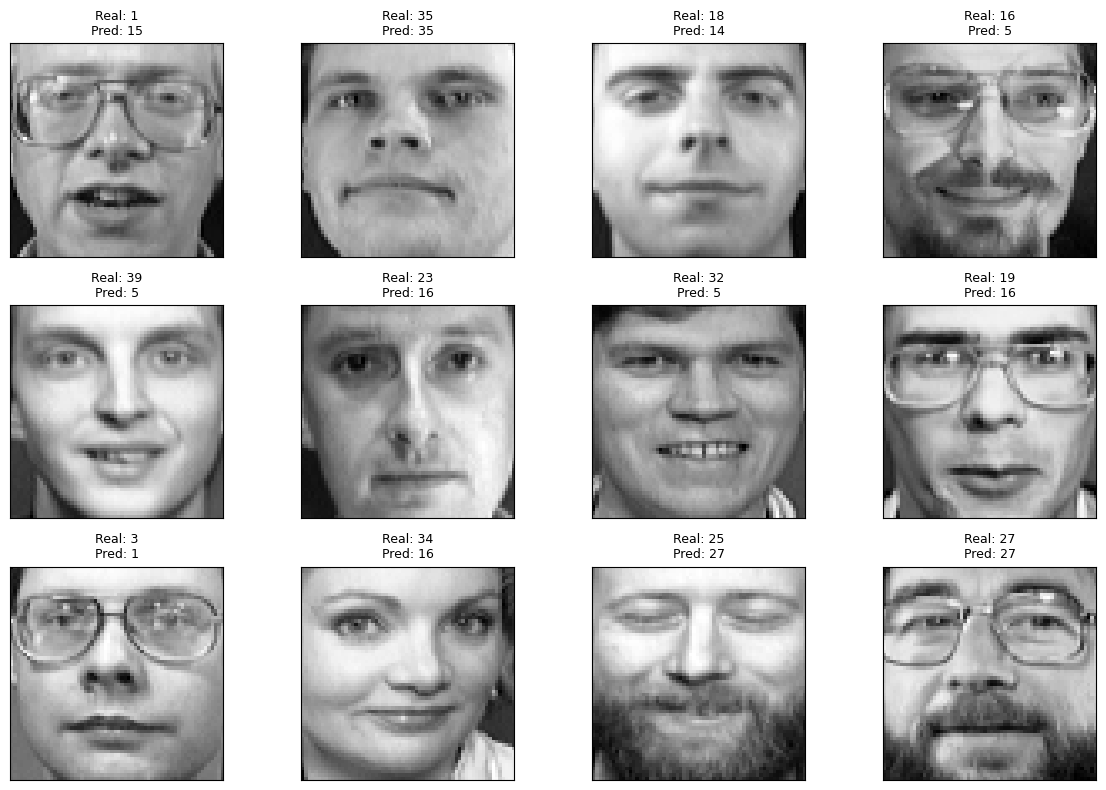

In [14]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexi?n final

Responde brevemente.

### 1. ?Cu?l fue el accuracy final del modelo?

**Respuesta:** **18.75%** en el conjunto reportado por `evaluate()`; loss **3.0590**.

### 2. ?Observaste overfitting? ?Qu? evidencia utilizaste?

**Respuesta:** Hay una brecha moderada: al final, accuracy de entrenamiento **27.50%** frente a validaci?n **18.75%**. La curva de validaci?n tambi?n fluct?a; esto indica generalizaci?n limitada y cierta tendencia a sobreajustar, aunque el modelo no llega a memorizar el entrenamiento.

### 3. ?Qu? ocurre cuando tenemos muchos par?metros pero pocos ejemplos de entrenamiento?

**Respuesta:** Aumenta el riesgo de que el modelo memorice el conjunto de entrenamiento, obtenga mejor resultado all? que en datos no vistos y generalice peor. Aqu? se entrenan 264,808 par?metros con solo 320 im?genes.

### 4. Despu?s de `Flatten()`, una cara de 64?64 se convierte en un vector de 4096 n?meros. ?Qu? informaci?n sobre la estructura de la imagen deja de representar expl?citamente esta transformaci?n?

**Respuesta:** La vecindad y organizaci?n espacial de los p?xeles y sus patrones locales dejan de estar representadas expl?citamente; las capas densas reciben posiciones del vector sin una estructura de imagen incorporada.

### 5. ?Crees que una arquitectura dise?ada espec?ficamente para im?genes podr?a aprovechar mejor la informaci?n espacial?

**Respuesta:** S?. Una CNN puede aprender filtros locales y compartirlos en distintas posiciones, aprovechando bordes, formas y otros patrones espaciales.

---

## Para pensar

Nuestra red recibe:

```text
64 ? 64
   ?
Flatten
   ?
4096 n?meros
   ?
Dense
```

Pero una imagen tiene una estructura espacial:

- p?xeles cercanos est?n relacionados,
- existen bordes,
- existen formas,
- existen patrones locales.

Una red fully-connected no incorpora expl?citamente esa estructura.

Esto motiva una arquitectura dise?ada espec?ficamente para im?genes:

> **Convolutional Neural Networks (CNNs)**


---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
